# INTRODUCTION #


## Problem Definition


<div style=" border-left: 5px solid #007BFF; padding: 15px; border-radius: 8px;">
    
The used car market in Morocco is growing rapidly, but prices remain largely **unstructured**.  
Car prices often vary depending on **negotiation**, **location**, or the **seller's perception**, creating uncertainty for both buyers and sellers.

This project builds a **Machine Learning model** to predict the **fair market price** of a used car in Morocco.  
The dataset contains **real Moroccan car listings** with features such as:

- **Vehicle attributes:** brand, model, year, mileage, fuel type, fiscal power  
- **Location:** city and district  
- **Options:** ABS, ESP, Bluetooth, power windows, etc.  

### Project Objectives
- Identify the **key factors** influencing car prices.  
- Provide **accurate predictions** for fair evaluations.  
- Help buyers, sellers, and platforms **make data-driven decisions**.  

### Outcome
A prediction tool that improves **trust** and **efficiency** in Morocco's used car market.





# DATA COLLECTION #


In [23]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

In [24]:
df=pd.read_csv("avito_car_dataset_ALL.csv", encoding='latin-1')

In [25]:
df.head()

,Unnamed: 0,Lien,Ville,Secteur,Marque,Modèle,Année-Modèle,Kilométrage,Type de carburant,Puissance fiscale,...,Caméra de recul,Vitres électriques,ABS,ESP,Régulateur de vitesse,Limiteur de vitesse,CD/MP3/Bluetooth,Ordinateur de bord,Verrouillage centralisé à distance,Prix
0,0,https://www.avito.ma/fr/massira_2/voitures/FIA...,Temara,Massira 2,Fiat,Punto,2007,200 000 - 249 999,Diesel,5,...,False,False,True,False,False,False,True,False,False,60000
1,1,https://www.avito.ma/fr/temara/voitures/Dacia_...,Temara,NaN,Dacia,Dokker Van,2013,400 000 - 449 999,Diesel,6,...,False,False,False,False,False,False,False,False,False,70000
2,2,https://www.avito.ma/fr/casablanca/voitures/Da...,Casablanca,NaN,Dacia,Dokker,2014,160 000 - 169 999,Diesel,6,...,False,False,False,False,False,False,False,False,False,90000
3,3,https://www.avito.ma/fr/casablanca/voitures/to...,Casablanca,NaN,Volkswagen,Touareg,2005,0 - 4 999,Diesel,10,...,False,False,False,False,False,False,False,False,False,90000
4,4,https://www.avito.ma/fr/dakhla/voitures/Toyota...,Dakhla,NaN,Toyota,Prado,2007,200 000 - 249 999,Diesel,12,...,False,False,True,False,False,False,True,False,False,97000


In [26]:
df.shape

(24776, 32)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24776 entries, 0 to 24775
Data columns (total 32 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Unnamed: 0                          24776 non-null  int64  
 1   Lien                                24776 non-null  object 
 2   Ville                               24776 non-null  object 
 3   Secteur                             10810 non-null  object 
 4   Marque                              24776 non-null  object 
 5   Modèle                              24776 non-null  object 
 6   Année-Modèle                        24776 non-null  int64  
 7   Kilométrage                         24776 non-null  object 
 8   Type de carburant                   24776 non-null  object 
 9   Puissance fiscale                   24776 non-null  int64  
 10  Boite de vitesses                   24776 non-null  object 
 11  Nombre de portes                    20396

In [28]:
df.isnull().sum()

Unnamed: 0                                0
Lien                                      0
Ville                                     0
Secteur                               13966
Marque                                    0
Modèle                                    0
Année-Modèle                              0
Kilométrage                               0
Type de carburant                         0
Puissance fiscale                         0
Boite de vitesses                         0
Nombre de portes                       4380
Origine                                5287
Première main                          6209
État                                   6678
Jantes aluminium                          0
Airbags                                   0
Climatisation                             0
Système de navigation/GPS                 0
Toit ouvrant                              0
Sièges cuir                               0
Radar de recul                            0
Caméra de recul                 

In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df.describe()

,Unnamed: 0,Année-Modèle,Puissance fiscale,Nombre de portes,Prix
count,24776.000000,24776.000000,24776.000000,20396.000000,2.477600e+04
mean,12387.500000,2011.844244,7.193938,4.905766,2.169588e+05
std,7152.359471,5.462925,1.574124,0.423789,6.749569e+06
min,0.000000,1990.000000,5.000000,3.000000,6.000000e+04
25%,6193.750000,2008.000000,6.000000,5.000000,7.500000e+04
50%,12387.500000,2013.000000,7.000000,5.000000,1.000000e+05
75%,18581.250000,2016.000000,8.000000,5.000000,1.400000e+05
max,24775.000000,2022.000000,14.000000,5.000000,6.120372e+08


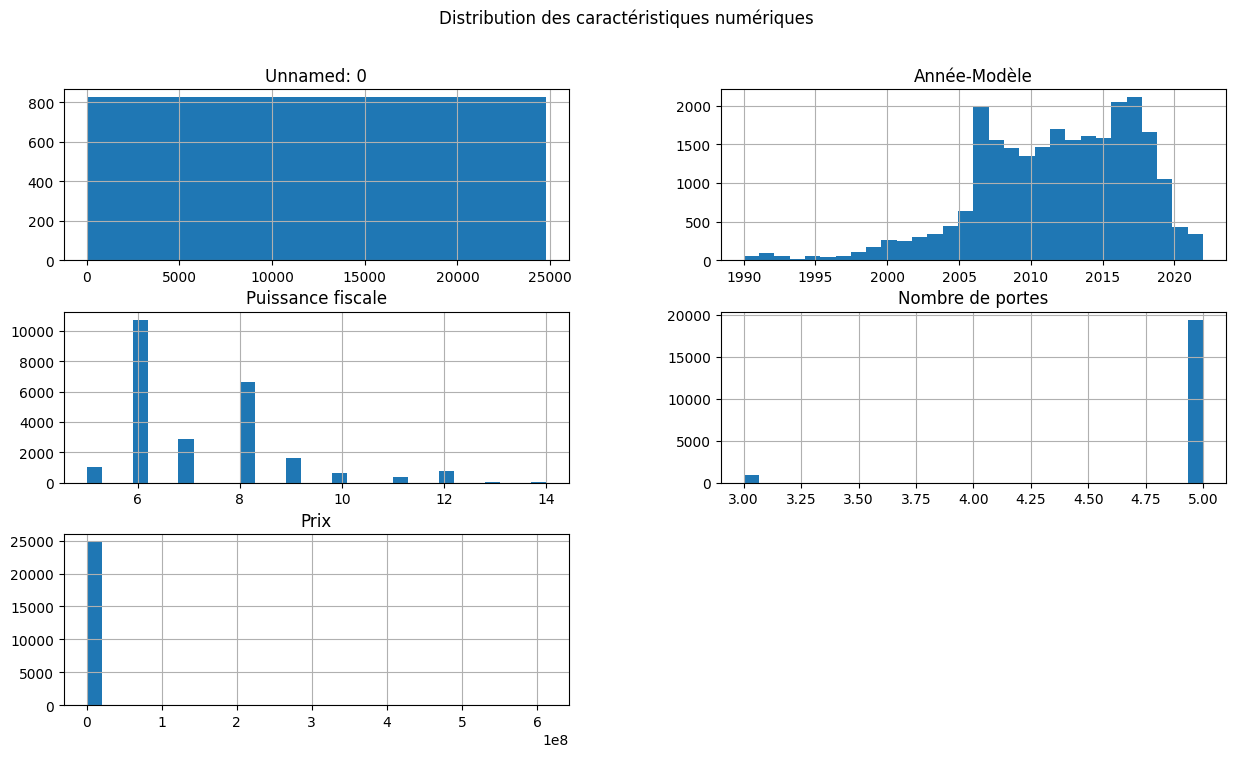

In [31]:
df.hist(bins=30,figsize=(15,8))
plt.suptitle('Distribution des caractéristiques numériques')
plt.show()

# DATA PREPROCESSING #

In [32]:
df['Boite de vitesses'].value_counts()

Boite de vitesses
Manuelle       17452
Automatique     4418
--              2906
Name: count, dtype: int64

In [33]:
df['Boite de vitesses']=df['Boite de vitesses'].replace(to_replace='--',value='Manuelle')
print(df['Boite de vitesses'].unique())

['Manuelle' 'Automatique']


In [34]:
df['Première main'].value_counts()

Première main
Non    11788
Oui     6779
Name: count, dtype: int64

In [35]:
df['Première main'] = df['Première main'].fillna('Non')

In [36]:
df['État'].value_counts()

État
Excellent      8761
Très bon       7402
Bon            1833
Correct          90
Pour Pièces       9
Endommagé         3
Name: count, dtype: int64

In [37]:
df['État'] = df['État'].fillna('Bon')

In [38]:
df['Origine'].value_counts()

Origine
WW au Maroc             14574
Dédouanée                3900
Importée neuve            949
Pas encore dédouanée       66
Name: count, dtype: int64

In [39]:
df['Origine']=df['Origine'].fillna('WW au Maroc')

In [40]:
df['Nombre de portes'].value_counts()

Nombre de portes
5.0    19435
3.0      961
Name: count, dtype: int64

In [41]:
df['Nombre de portes']= df['Nombre de portes'].replace(to_replace=' ',value='5')

In [42]:
df['Nombre de portes'].value_counts()

Nombre de portes
5.0    19435
3.0      961
Name: count, dtype: int64

In [43]:
useless_cols =['Secteur','Ville','Lien','Unnamed: 0']
df=df.drop(columns=useless_cols , errors='ignore')
df.columns

Index(['Marque', 'Modèle', 'Année-Modèle', 'Kilométrage', 'Type de carburant',
       'Puissance fiscale', 'Boite de vitesses', 'Nombre de portes', 'Origine',
       'Première main', 'État', 'Jantes aluminium', 'Airbags', 'Climatisation',
       'Système de navigation/GPS', 'Toit ouvrant', 'Sièges cuir',
       'Radar de recul', 'Caméra de recul', 'Vitres électriques', 'ABS', 'ESP',
       'Régulateur de vitesse', 'Limiteur de vitesse', 'CD/MP3/Bluetooth',
       'Ordinateur de bord', 'Verrouillage centralisé à distance', 'Prix'],
      dtype='object')

In [44]:
df=df.dropna()

In [45]:
df.isnull().sum()

Marque                                0
Modèle                                0
Année-Modèle                          0
Kilométrage                           0
Type de carburant                     0
Puissance fiscale                     0
Boite de vitesses                     0
Nombre de portes                      0
Origine                               0
Première main                         0
État                                  0
Jantes aluminium                      0
Airbags                               0
Climatisation                         0
Système de navigation/GPS             0
Toit ouvrant                          0
Sièges cuir                           0
Radar de recul                        0
Caméra de recul                       0
Vitres électriques                    0
ABS                                   0
ESP                                   0
Régulateur de vitesse                 0
Limiteur de vitesse                   0
CD/MP3/Bluetooth                      0


In [46]:
df.shape

(20396, 28)

In [47]:
splited = df['Kilométrage'].str.split("-", n = 1 , expand = True)
splited[0] = splited[0].str.replace(' ','').astype(int)
splited[1] = splited[1].str.replace(' ','').astype(int)
df['Kilométrage'] = (splited[1] + splited[0])/2

In [48]:
df.head()

,Marque,Modèle,Année-Modèle,Kilométrage,Type de carburant,Puissance fiscale,Boite de vitesses,Nombre de portes,Origine,Première main,...,Caméra de recul,Vitres électriques,ABS,ESP,Régulateur de vitesse,Limiteur de vitesse,CD/MP3/Bluetooth,Ordinateur de bord,Verrouillage centralisé à distance,Prix
0,Fiat,Punto,2007,224999.5,Diesel,5,Manuelle,5.0,WW au Maroc,Non,...,False,False,True,False,False,False,True,False,False,60000
1,Dacia,Dokker Van,2013,424999.5,Diesel,6,Manuelle,3.0,WW au Maroc,Non,...,False,False,False,False,False,False,False,False,False,70000
2,Dacia,Dokker,2014,164999.5,Diesel,6,Manuelle,5.0,WW au Maroc,Non,...,False,False,False,False,False,False,False,False,False,90000
3,Volkswagen,Touareg,2005,2499.5,Diesel,10,Automatique,5.0,WW au Maroc,Oui,...,False,False,False,False,False,False,False,False,False,90000
4,Toyota,Prado,2007,224999.5,Diesel,12,Manuelle,5.0,WW au Maroc,Non,...,False,False,True,False,False,False,True,False,False,97000


In [50]:
df = df.replace({True: 1 , False: 0})

In [52]:
df['Première main']= df ['Première main'].replace({'Oui': 1 , 'Non': 0})

In [53]:
df.head()

,Marque,Modèle,Année-Modèle,Kilométrage,Type de carburant,Puissance fiscale,Boite de vitesses,Nombre de portes,Origine,Première main,...,Caméra de recul,Vitres électriques,ABS,ESP,Régulateur de vitesse,Limiteur de vitesse,CD/MP3/Bluetooth,Ordinateur de bord,Verrouillage centralisé à distance,Prix
0,Fiat,Punto,2007,224999.5,Diesel,5,Manuelle,5.0,WW au Maroc,0,...,0,0,1,0,0,0,1,0,0,60000
1,Dacia,Dokker Van,2013,424999.5,Diesel,6,Manuelle,3.0,WW au Maroc,0,...,0,0,0,0,0,0,0,0,0,70000
2,Dacia,Dokker,2014,164999.5,Diesel,6,Manuelle,5.0,WW au Maroc,0,...,0,0,0,0,0,0,0,0,0,90000
3,Volkswagen,Touareg,2005,2499.5,Diesel,10,Automatique,5.0,WW au Maroc,1,...,0,0,0,0,0,0,0,0,0,90000
4,Toyota,Prado,2007,224999.5,Diesel,12,Manuelle,5.0,WW au Maroc,0,...,0,0,1,0,0,0,1,0,0,97000


In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20396 entries, 0 to 24774
Data columns (total 28 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Marque                              20396 non-null  object 
 1   Modèle                              20396 non-null  object 
 2   Année-Modèle                        20396 non-null  int64  
 3   Kilométrage                         20396 non-null  float64
 4   Type de carburant                   20396 non-null  object 
 5   Puissance fiscale                   20396 non-null  int64  
 6   Boite de vitesses                   20396 non-null  object 
 7   Nombre de portes                    20396 non-null  float64
 8   Origine                             20396 non-null  object 
 9   Première main                       20396 non-null  int64  
 10  État                                20396 non-null  object 
 11  Jantes aluminium                    20396 non-

In [55]:
df.describe().round(2)

,Année-Modèle,Kilométrage,Puissance fiscale,Nombre de portes,Première main,Jantes aluminium,Airbags,Climatisation,Système de navigation/GPS,Toit ouvrant,...,Caméra de recul,Vitres électriques,ABS,ESP,Régulateur de vitesse,Limiteur de vitesse,CD/MP3/Bluetooth,Ordinateur de bord,Verrouillage centralisé à distance,Prix
count,20396.00,20396.00,20396.00,20396.00,20396.00,20396.0,20396.00,20396.00,20396.0,20396.0,...,20396.0,20396.0,20396.00,20396.00,20396.0,20396.0,20396.00,20396.0,20396.0,2.039600e+04
mean,2011.83,133130.51,7.16,4.91,0.31,0.0,0.66,0.68,0.0,0.0,...,0.0,0.0,0.61,0.43,0.0,0.0,0.60,0.0,0.0,2.311635e+05
std,5.44,89297.93,1.54,0.42,0.46,0.0,0.47,0.46,0.0,0.0,...,0.0,0.0,0.49,0.49,0.0,0.0,0.49,0.0,0.0,7.437302e+06
min,1990.00,2499.50,5.00,3.00,0.00,0.0,0.00,0.00,0.0,0.0,...,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.0,0.0,6.000000e+04
25%,2008.00,62499.50,6.00,5.00,0.00,0.0,0.00,0.00,0.0,0.0,...,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.0,0.0,7.500000e+04
50%,2012.00,124999.50,7.00,5.00,0.00,0.0,1.00,1.00,0.0,0.0,...,0.0,0.0,1.00,0.00,0.0,0.0,1.00,0.0,0.0,1.000000e+05
75%,2016.00,194999.50,8.00,5.00,1.00,0.0,1.00,1.00,0.0,0.0,...,0.0,0.0,1.00,1.00,0.0,0.0,1.00,0.0,0.0,1.380000e+05
max,2022.00,474999.50,14.00,5.00,1.00,0.0,1.00,1.00,0.0,0.0,...,0.0,0.0,1.00,1.00,0.0,0.0,1.00,0.0,0.0,6.120372e+08


In [56]:
df['Prix'].describe()

count    2.039600e+04
mean     2.311635e+05
std      7.437302e+06
min      6.000000e+04
25%      7.500000e+04
50%      1.000000e+05
75%      1.380000e+05
max      6.120372e+08
Name: Prix, dtype: float64

In [57]:
prix_limite = 1000000
df = df[df['Prix'] < prix_limite]

In [58]:
df['Prix'].describe()

count     20324.00000
mean     122451.97343
std       80690.79504
min       60000.00000
25%       75000.00000
50%      100000.00000
75%      138000.00000
max      950000.00000
Name: Prix, dtype: float64

In [59]:
df['Marque'].value_counts()

Marque
Volkswagen       2777
Renault          2753
Dacia            2499
Peugeot          1654
Mercedes-Benz    1525
Ford             1362
Hyundai          1359
Citroen          1017
Fiat              879
Toyota            782
Audi              592
Opel              485
Nissan            457
BMW               456
Kia               437
Skoda             311
Seat              267
Land Rover        231
Jeep              154
Alfa Romeo        109
Chevrolet          76
mini               73
Suzuki             69
Name: count, dtype: int64

In [60]:
df.drop(df[ (df['Marque'] == "Suzuki") | (df['Marque'] == "mini") | (df['Marque'] == "Alfa Romeo") | (df['Marque'] == "Chevrolet") ].index, inplace=True)

# EXPLORATORY DATA ANALYSIS (EDA) #

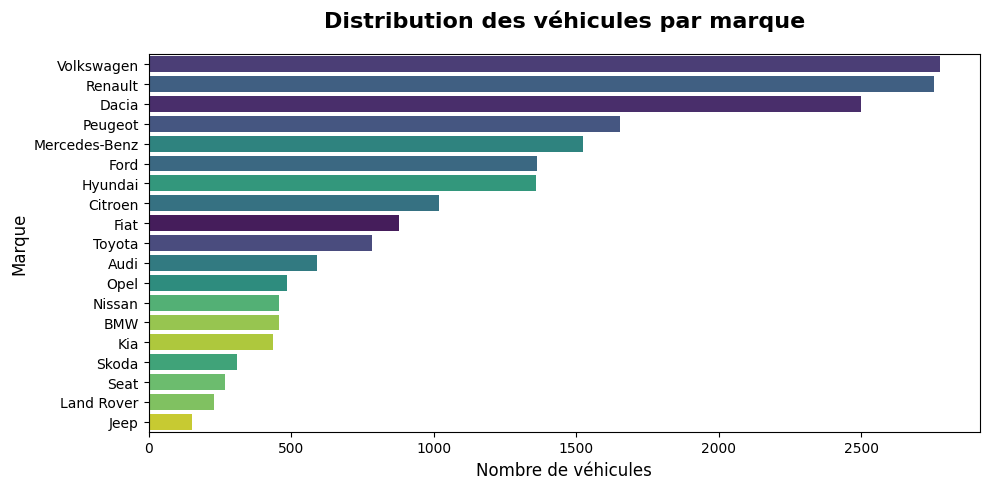

In [61]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, y='Marque', hue='Marque', order=df['Marque'].value_counts().index,  palette='viridis', legend=False)
plt.title('Distribution des véhicules par marque', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Nombre de véhicules', fontsize=12)
plt.ylabel('Marque', fontsize=12)
plt.tight_layout()
plt.show()

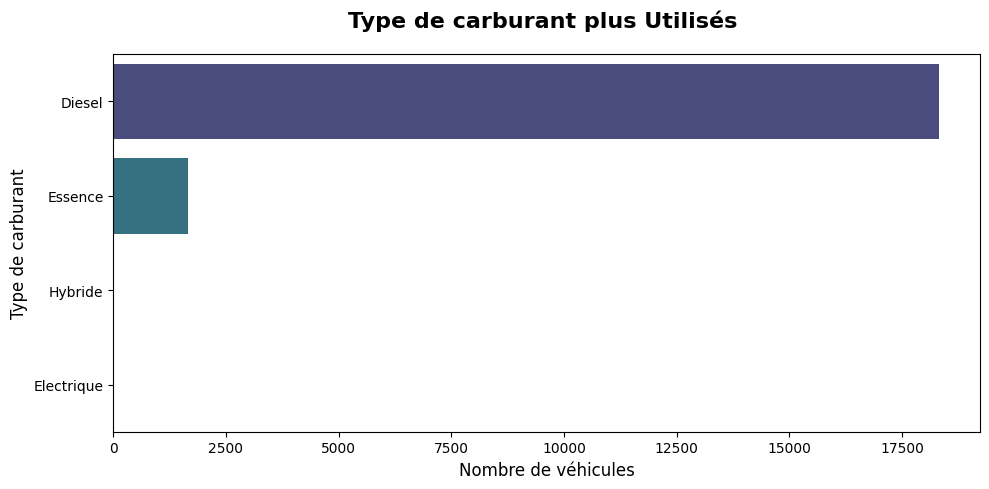

In [62]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, y='Type de carburant', hue='Type de carburant', palette='viridis',  legend=False)
plt.title('Type de carburant plus Utilisés ', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Nombre de véhicules', fontsize=12)
plt.ylabel('Type de carburant', fontsize=12)
plt.tight_layout()
plt.show()

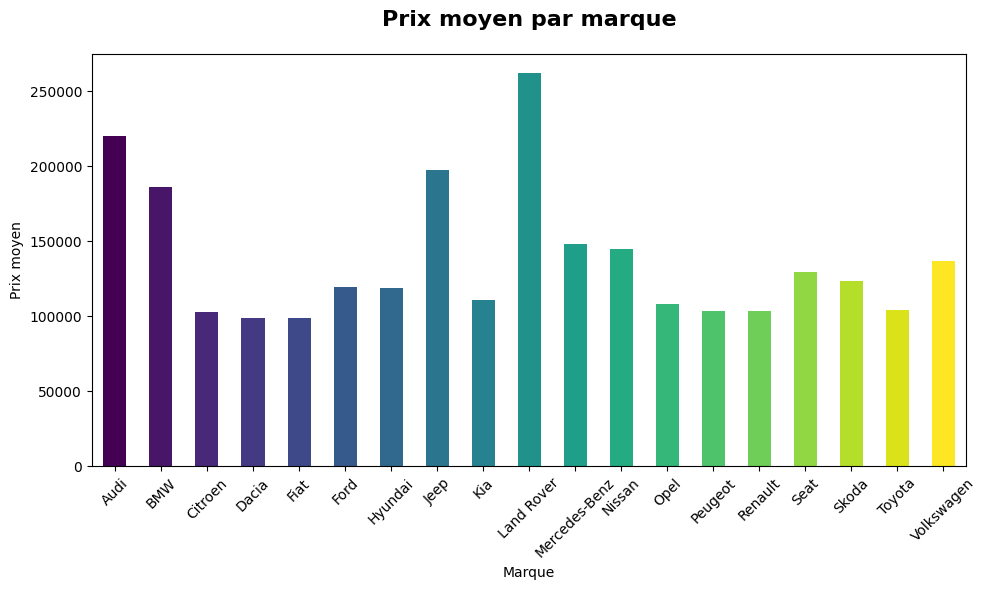

In [63]:
plt.figure(figsize=(10,6))
df.groupby('Marque')['Prix'].mean().plot(kind='bar', color=plt.cm.viridis(np.linspace(0, 1, len(df['Marque'].unique()))))
plt.title('Prix moyen par marque',fontsize = 16 , fontweight ='bold' ,pad=20)
plt.xlabel('Marque')
plt.ylabel('Prix moyen')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

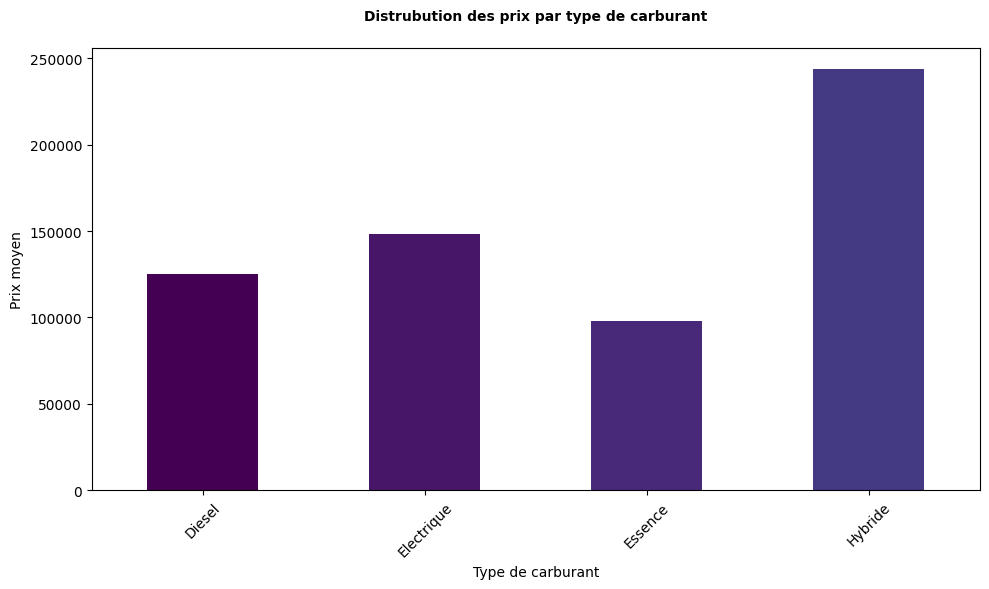

In [64]:
plt.figure(figsize=(10,6))
df.groupby('Type de carburant')['Prix'].mean().plot(kind='bar', color=plt.cm.viridis(np.linspace(0, 1, len(df['Marque'].unique()))))
plt.title('Distrubution des prix par type de carburant',fontsize=10 , fontweight='bold', pad=20)
plt.xlabel('Type de carburant')
plt.ylabel('Prix moyen')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

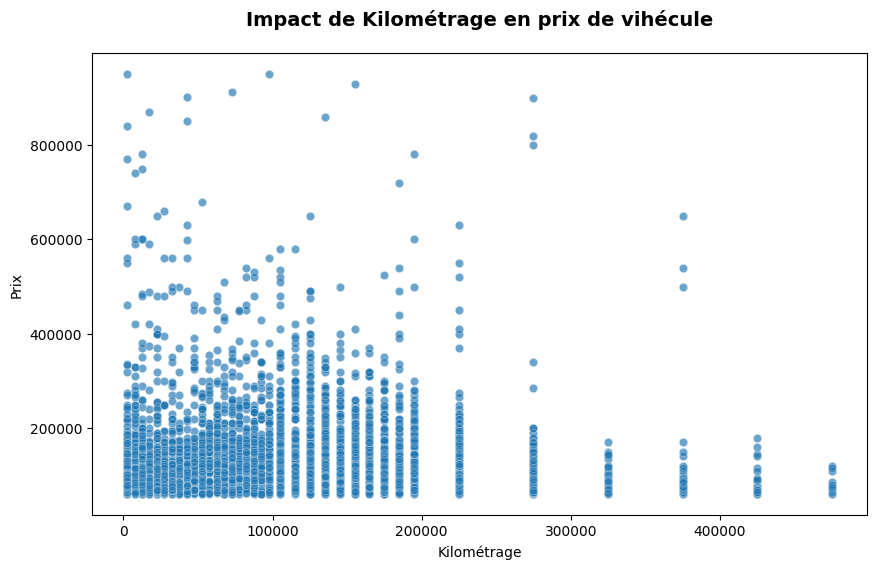

In [65]:
plt.figure(figsize=(10,6))
sns.scatterplot(x="Kilométrage", y="Prix", data=df, alpha=0.3)
plt.title("Impact de Kilométrage en prix de vihécule", fontsize=14 ,fontweight='bold',pad=20)
plt.show()

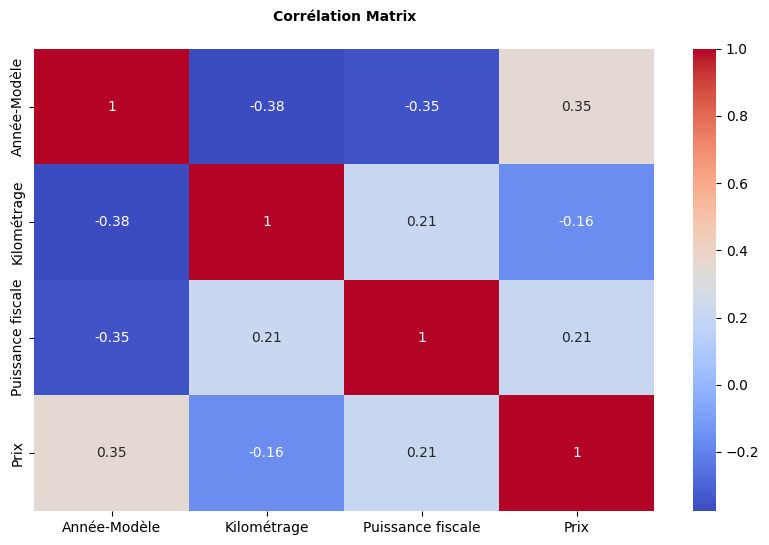

In [67]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])
non_binary_df = numeric_df.loc[:, numeric_df.nunique() > 2]
corr_matrix = non_binary_df.corr()
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix, annot=True , cmap ="coolwarm")
plt.title('Corrélation Matrix' , fontsize=10,fontweight='bold',pad=20)
plt.show()


# MODELING #

##  1 . Importing Libreries ##

In [72]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

 ## 2 . Feature Engineering ##

In [73]:
# Cibles et variables
X = df.drop("Prix", axis=1)
y = df["Prix"]

In [74]:
# Encodage des variables catégorielles
for col in X.select_dtypes(include="object").columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))

In [75]:
# Normalisation (utile pour les modèles linéaires et SVR, pas indispensable pour arbres)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [76]:
# Split train / test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

## 3 . Defining the models ##

In [77]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42),
    "LightGBM": lgb.LGBMRegressor(n_estimators=300, learning_rate=0.1, random_state=42),
    "CatBoost": CatBoostRegressor(iterations=300, learning_rate=0.1, depth=6, silent=True, random_state=42)
}

 ## 4 . Train & Evaluate ##

In [78]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append([name, mae, rmse, r2])


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000934 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 367
[LightGBM] [Info] Number of data points in the train set: 15997, number of used features: 16
[LightGBM] [Info] Start training from score 122866.287991


C:\Users\VIET\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


##  5 . Results ##

In [79]:
results_df = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R²"])
print(results_df.sort_values(by="R²", ascending=False))

               Model           MAE          RMSE        R²
3      Random Forest   5333.093180  17776.865364  0.951424
4            XGBoost  11284.658203  27110.057174  0.887028
5           LightGBM  14616.105556  35726.802899  0.803801
6           CatBoost  17585.584982  43046.488119  0.715171
1              Ridge  33003.289114  64800.433548  0.354548
2              Lasso  33003.487205  64800.437153  0.354548
0  Linear Regression  33003.487560  64800.437228  0.354548


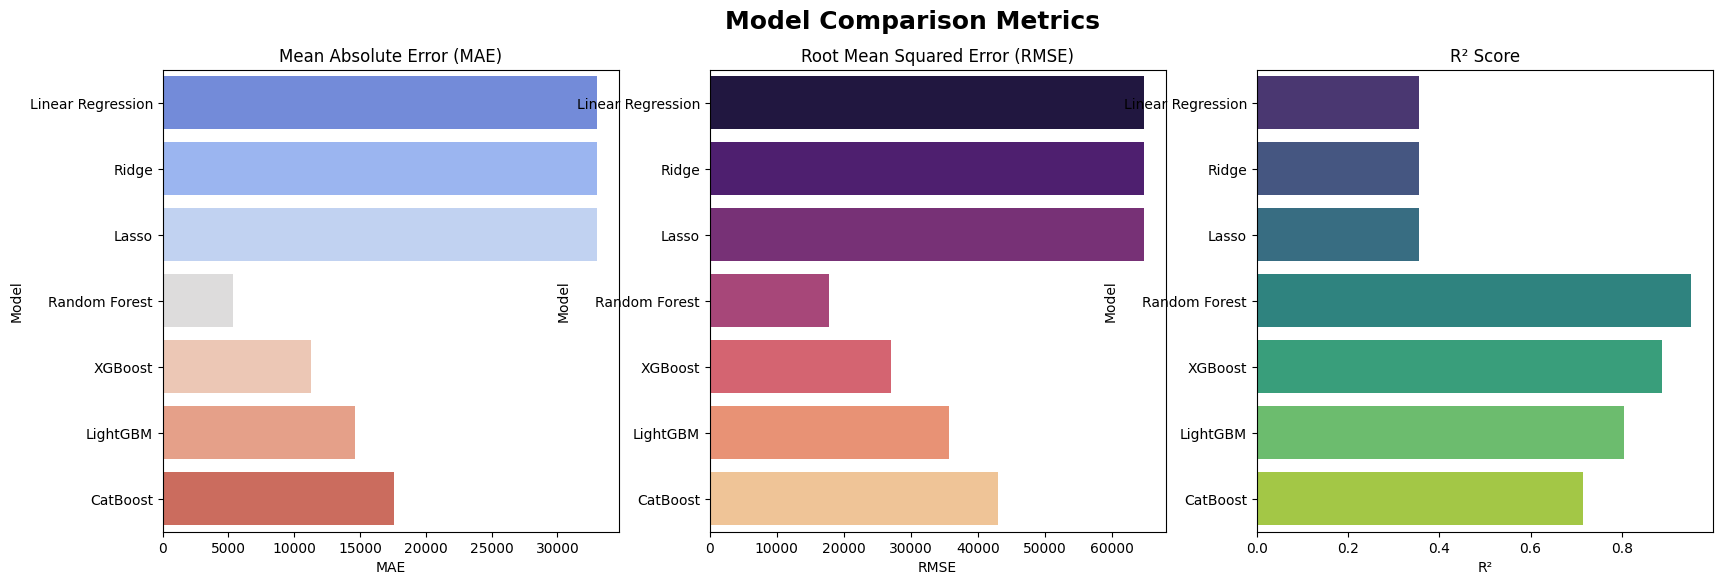

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(20,6))

# MAE
sns.barplot(x="MAE", y="Model", data=results_df ,hue='Model' ,ax=axes[0], palette="coolwarm", legend=False)
axes[0].set_title("Mean Absolute Error (MAE)")

# RMSE
sns.barplot(x="RMSE", y="Model", data=results_df, hue='Model' , ax=axes[1], palette="magma", legend=False)
axes[1].set_title("Root Mean Squared Error (RMSE)")

# R²
sns.barplot(x="R²", y="Model", data=results_df ,hue='Model' , ax=axes[2], palette="viridis", legend=False)
axes[2].set_title("R² Score")

plt.suptitle("Model Comparison Metrics", fontsize=18, weight="bold")
plt.show()

## 6 . Saving the Pipeline ##

In [82]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pickle

# Séparer features et target
X = df.drop("Prix", axis=1)
y = df["Prix"]

# Identifier colonnes numériques et catégorielles
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

# Créer le préprocesseur pour encodage
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),  # Ajouter pour les numériques
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Créer le pipeline complet
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=200, random_state=42))
])

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entraîner le pipeline
pipeline.fit(X_train, y_train)

# Tester le pipeline
score = pipeline.score(X_test, y_test)
print(f"Score du modèle: {score}")

# Sauvegarder le pipeline complet
with open("C:/Users/VIET/Downloads/car__model.pkl", "wb") as f:
    pickle.dump(pipeline, f)

print("Pipeline sauvegardé avec succès !")

# Sauvegarder  les noms des colonnes
with open("C:/Users/VIET/Downloads/feature_names.pkl", "wb") as f:
    pickle.dump(X.columns.tolist(), f)

Score du modèle: 0.950816094805105
Pipeline sauvegardé avec succès !
